# INF2006 Big Data Project — Spark pipeline, model and analytics (AWS EMR)

**Kernel:** PySpark (JupyterHub on EMR `emr-7.10.0`). **Run it with:** `Kernel → Restart & Run All` (or run the cells top to bottom).
**Before this notebook** the two shell stages must already have run on the primary node (they use Hadoop Streaming and Hive, which need the cluster's command line):

| Stage | Engine | Script (relative path in the ZIP) | Output used here |
|---|---|---|---|
| 1 | S3 → HDFS (DistCp) | `scripts/stage1_stage_to_hdfs.sh` | `/raw/prices/<version>/`, `/raw/gdelt/<version>/` |
| 2 | Hadoop Streaming + Hive on Tez | `scripts/stage2_streaming_and_hive.sh` | Hive database `inf2006` (`prices_typed`, `gdelt_daily_typed`, …) |
| 3–5 | **PySpark / Spark ML (this notebook)** | `notebooks/inf2006_pipeline.ipynb` | cleaned/rejected data, splits, models, analytics, timings |

`scripts/emr_run_all.sh` runs stages 1–2 for you in one command. Full step-by-step guide: `docs/RUN_ON_EMR.md` (this is Appendix A).

| Section | Brief reference |
|---|---|
| 0 Setup, environment, helper functions | Cloud resource constraints, reproducibility |
| 1 Corpus checks (Task 1) | Task 1.2 |
| 2 Cleaning, features, chronological splits (Task 2) | Task 2.1–2.3 |
| 3 Models: weekly direction + high-volatility weeks (Task 3) | Task 3.1–3.3 |
| 4 Analytics (Task 4) | Task 4.1–4.3 |
| 5 Performance, memory, repetitions (Section 6 of the report) | Cloud resource constraints |
| 6 Saved-model reload in a fresh session | Task 3.3 |
| 7 Verification record | Submission requirements |

In [26]:
%%configure -f
{
  "conf": {
    "spark.executor.instances": "2",
    "spark.executor.cores": "2",
    "spark.executor.memory": "6g",
    "spark.executor.memoryOverhead": "2g",
    "spark.driver.memory": "2g",
    "spark.dynamicAllocation.enabled": "false",
    "spark.sql.catalogImplementation": "hive",

    "spark.yarn.dist.archives": "s3://inf2006-team07-bigdata-1-310947418945-us-east-1-an/dependencies/spark-numpy-env.tar.gz#environment",
    "spark.pyspark.python": "./environment/bin/python",
    "spark.executorEnv.PYSPARK_PYTHON": "./environment/bin/python"
  }
}

Starting Spark application


ID,YARN Application ID,Kind,State,Spark UI,Driver log,User,Current session?
2,application_1793775642011_0010,pyspark,idle,Link,Link,None,✔


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

SparkSession available as 'spark'.


ID,YARN Application ID,Kind,State,Spark UI,Driver log,User,Current session?
2,application_1793775642011_0010,pyspark,idle,Link,Link,None,✔


## 0. Setup

### 0.1 Parameters (the only cell you may need to edit)

* `VERSION` — the raw-data version folder staged in HDFS (`/raw/prices/<VERSION>`). Must match what you gave Stage 1 and Stage 2.
* `BUCKET` — your S3 bucket (outputs and models are saved there so they survive cluster termination).
* `ACTIVE_CONFIG` — `"reference"` or `"alternative"` (the justified software alternative, Section 5). Everything else stays the same.

In [27]:
import json, time, datetime, math, statistics, os, socket, sys, itertools
from pyspark.sql import functions as F, Window
from pyspark.sql.types import StringType

# ------------------------------------------------------------------ parameters
VERSION       = "v2026-10-29-q1-2016"            # raw-data version (docs/input_profiles.md); Q1-2016 profile: "v2026-10-29-q1-2016"
BUCKET        = "inf2006-team07-bigdata-1-310947418945-us-east-1-an"
ACTIVE_CONFIG = "reference"              # "reference" | "alternative"
REPETITIONS   = 3                        # brief: median of three repetitions

# ------------------------------------------------------------------ fixed project settings
SEED          = 42
TRAIN_END, VAL_START, VAL_END, TEST_START = "2015-12-31", "2016-01-01", "2016-12-31", "2017-01-01"
DATA_END      = "2017-12-29"             # last day of the assessed price scope
MIN_HISTORY   = 61                       # bars of history before the first usable weekly anchor
HIGH_VOL_Q    = 0.67                     # "high-volatility week" = top third of TRAIN next-week volatility
TOL           = 1e-9                     # numerical tolerance for the saved-model reload check
CONFIGS = {                              # software-only comparison (hardware, release, replication fixed)
    "reference":   {"shuffle_partitions": 200, "aqe": False,
                    "why": "Spark default shuffle partitions; fixed 2 executors x 2 cores x 6 GiB"},
    "alternative": {"shuffle_partitions": 8,   "aqe": True,
                    "why": "8 partitions ~ 2x total cores for a ~30 MB shuffle; adaptive execution coalesces small partitions"},
}

IS_EMR = "amzn" in spark.version
sc = spark.sparkContext
spark.conf.set("spark.sql.shuffle.partitions", str(CONFIGS[ACTIVE_CONFIG]["shuffle_partitions"]))
spark.conf.set("spark.sql.adaptive.enabled", str(CONFIGS[ACTIVE_CONFIG]["aqe"]).lower())

if IS_EMR:
    PREP        = f"hdfs:///prepared/{VERSION}/{ACTIVE_CONFIG}"
    MODELS_HDFS = f"hdfs:///models/{VERSION}"
    OUT_CANDIDATES = [f"s3://{BUCKET}/notebook_outputs/{VERSION}", f"hdfs:///project/notebook_outputs/{VERSION}"]
else:                                    # local development only (never counts as the assessed run)
    LOCAL_ROOT  = os.path.abspath("work/nb")
    PREP        = f"file://{LOCAL_ROOT}/prepared/{VERSION}/{ACTIVE_CONFIG}"
    MODELS_HDFS = f"file://{LOCAL_ROOT}/models/{VERSION}"
    OUT_CANDIDATES = [f"file://{LOCAL_ROOT}/out/{VERSION}"]
    LOCAL_PRICES = "data/raw/prices/all_stocks_5yr.csv"
    LOCAL_GDELT_AUDIT = {"v2026-10-27": "evidence/local/streaming_gdelt_audit.tsv",
                         "v2026-10-29-q1-2016": "evidence/local/q1_2016/streaming_gdelt_audit.tsv"}.get(
                             VERSION, "evidence/local/streaming_gdelt_audit.tsv")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

### 0.2 Helper functions (stage timer, file writer, checks)

* `stage(...)` times each pipeline stage (wall clock) and records it for Section 5.
* `write_text` / `read_text` write small evidence files to S3 / HDFS through Hadoop's file API (no extra libraries).
* `check(...)` records one verification line: check, expected, actual, pass/fail.

In [28]:
def utc_now():
    return datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")

# ---- output location: S3 if writable (survives cluster termination), else HDFS
def write_text(path, text):
    jvm, conf = spark._jvm, spark._jsc.hadoopConfiguration()
    p = jvm.org.apache.hadoop.fs.Path(path)
    out = p.getFileSystem(conf).create(p, True)
    out.write(bytearray(text.encode("utf-8")))
    out.close()

def read_text(path):
    return "\n".join(r[0] for r in spark.read.text(path).collect())

OUT = None
for cand in OUT_CANDIDATES:
    try:
        write_text(f"{cand}/_write_test.txt", utc_now())
        OUT = cand
        break
    except Exception as ex:
        print(f"WARNING: cannot write to {cand}: {str(ex)[:120]}")
assert OUT, "No writable output location. Check the S3 bucket name / EMR role permissions (docs/RUN_ON_EMR.md, Troubleshooting)."
MODELS_OUT = f"{OUT}/models"
EV = f"{OUT}/evidence/{ACTIVE_CONFIG}"
print("outputs  :", OUT)
print("prepared :", PREP)
print("models   :", MODELS_HDFS, "and", MODELS_OUT)

def save_json(name, obj):
    write_text(f"{EV}/{name}", json.dumps(obj, indent=2, default=str))

# ---- stage timer
CURRENT_LOG = []
class stage:
    def __init__(self, name, **meta):
        self.name, self.meta = name, dict(meta)
    def __enter__(self):
        self.t0, self.start = time.time(), utc_now()
        return self
    def __exit__(self, exc_type, exc, tb):
        rec = {"stage": self.name, "start_utc": self.start, "end_utc": utc_now(),
               "seconds": round(time.time() - self.t0, 2), "ok": exc_type is None, **self.meta}
        CURRENT_LOG.append(rec)
        print(f"[stage] {self.name}: {rec['seconds']} s" + ("" if rec["ok"] else "  FAILED"))
        return False

# ---- verification record
CHECKS = []
def check(name, expected, actual, ok=None, evidence=""):
    ok = (expected == actual) if ok is None else bool(ok)
    CHECKS.append({"check": name, "expected": str(expected), "actual": str(actual), "passed": ok, "evidence": evidence})
    print(("PASS  " if ok else "FAIL  ") + f"{name}: expected={expected} actual={actual}")
    return ok

def show(df, n=20):
    df.show(n, truncate=False)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

outputs  : s3://inf2006-team07-bigdata-1-310947418945-us-east-1-an/notebook_outputs/v2026-10-29-q1-2016
prepared : hdfs:///prepared/v2026-10-29-q1-2016/reference
models   : hdfs:///models/v2026-10-29-q1-2016 and s3://inf2006-team07-bigdata-1-310947418945-us-east-1-an/notebook_outputs/v2026-10-29-q1-2016/models

### 0.3 Environment and allocation (recorded as evidence)

In [29]:
conf_keys = ["spark.executor.instances", "spark.executor.cores", "spark.executor.memory", "spark.executor.memoryOverhead",
             "spark.driver.memory", "spark.dynamicAllocation.enabled", "spark.sql.shuffle.partitions",
             "spark.sql.adaptive.enabled", "spark.sql.catalogImplementation"]
def _conf(k):
    try:
        return spark.conf.get(k)
    except Exception:
        return "<unset>"

ENVIRONMENT = {
    "run_started_utc": utc_now(), "is_emr": IS_EMR, "spark_version": spark.version, "python": sys.version.split()[0],
    "application_id": sc.applicationId, "master": sc.master, "driver_host": socket.gethostname(),
    "version": VERSION, "active_config": ACTIVE_CONFIG, "config_note": CONFIGS[ACTIVE_CONFIG],
    "seed": SEED, "splits": {"train_end": TRAIN_END, "val": [VAL_START, VAL_END], "test_start": TEST_START, "data_end": DATA_END},
    "spark_conf": {k: _conf(k) for k in conf_keys},
}
print(json.dumps(ENVIRONMENT, indent=2))
save_json("environment.json", ENVIRONMENT)
if not IS_EMR:
    print("\n*** LOCAL DEVELOPMENT RUN - this is NOT the assessed EMR run ***")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

{
  "run_started_utc": "2026-11-04T08:23:02+00:00",
  "is_emr": true,
  "spark_version": "3.5.5-amzn-1",
  "python": "3.9.25",
  "application_id": "application_1793775642011_0010",
  "master": "yarn",
  "driver_host": "ip-172-31-30-98.ec2.internal",
  "version": "v2026-10-29-q1-2016",
  "active_config": "reference",
  "config_note": {
    "shuffle_partitions": 200,
    "aqe": false,
    "why": "Spark default shuffle partitions; fixed 2 executors x 2 cores x 6 GiB"
  },
  "seed": 42,
  "splits": {
    "train_end": "2015-12-31",
    "val": [
      "2016-01-01",
      "2016-12-31"
    ],
    "test_start": "2017-01-01",
    "data_end": "2017-12-29"
  },
  "spark_conf": {
    "spark.executor.instances": "2",
    "spark.executor.cores": "2",
    "spark.executor.memory": "6g",
    "spark.executor.memoryOverhead": "2g",
    "spark.driver.memory": "2g",
    "spark.dynamicAllocation.enabled": "false",
    "spark.sql.shuffle.partitions": "200",
    "spark.sql.adaptive.enabled": "false",
    "spar

## 1. Corpus checks (Task 1)

The raw corpus was staged and verified by `scripts/stage1_stage_to_hdfs.sh` (bytes, lines and SHA-256 read back from HDFS → `evidence/emr_ref_m5xlarge/stage1_hdfs_inventory.csv`) and audited by `scripts/stage2_streaming_and_hive.sh` (Hadoop Streaming + Hive on Tez). Here the **Spark** engine independently re-derives the same quality numbers from the Hive table `inf2006.prices_typed`, so three engines (Hive, Spark, local Python) must agree.

In [31]:
def load_prices_typed():
    """Hive table inf2006.prices_typed (EMR). Local development: the same schema built from the CSV."""
    if IS_EMR:
        return spark.table("inf2006.prices_typed")
    return (spark.read.option("header", True).csv(LOCAL_PRICES)
            .select(F.col("Name").alias("ticker"), F.to_date("date").alias("trade_date"),
                    F.year(F.to_date("date")).alias("yr"),
                    *[F.col(c).cast("double").alias(c) for c in ["open", "high", "low", "close", "volume"]]))

def load_gdelt_daily():
    """Hive table inf2006.gdelt_daily_typed (date_added, events, avg_tone, lag_events). Local: from the streaming audit TSV."""
    if IS_EMR:
        return spark.table("inf2006.gdelt_daily_typed")
    raw = spark.read.option("sep", "\t").csv(LOCAL_GDELT_AUDIT).toDF("audit_key", "events", "avg_tone", "lag_events")
    return (raw.where(F.col("audit_key").rlike("^[0-9]{8}$"))
            .select(F.to_date("audit_key", "yyyyMMdd").alias("date_added"), F.col("events").cast("long").alias("events"),
                    F.col("avg_tone").cast("double").alias("avg_tone"), F.col("lag_events").cast("long").alias("lag_events")))

if IS_EMR:
    tables = [r.tableName for r in spark.sql("SHOW TABLES IN inf2006").collect()]
    print("Hive tables in inf2006:", tables)
    missing = [t for t in ("prices_typed", "gdelt_daily_typed", "raw_prices_quality") if t not in tables]
    assert not missing, (f"Hive tables {missing} not found. Stage 2 has not been run on this cluster: run "
                         "'bash scripts/emr_run_all.sh' on the primary node first (docs/RUN_ON_EMR.md, step 6).")

raw_prices = load_prices_typed()
with stage("1a Spark quality audit of prices_typed") as st:
    num = ["open", "high", "low", "close", "volume"]
    q = raw_prices.agg(
        F.count("*").alias("rows_total"), F.countDistinct("ticker").alias("tickers"),
        F.min("trade_date").cast("string").alias("date_min"), F.max("trade_date").cast("string").alias("date_max"),
        F.sum(F.when(F.col("trade_date") <= F.lit(DATA_END).cast("date"), 1).otherwise(0)).alias("rows_up_to_2017_12_29"),
        *[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(f"empty_{c}") for c in num],
        F.sum(F.when(F.col("open").isNotNull() & F.col("high").isNotNull() & F.col("low").isNotNull() & F.col("close").isNotNull()
                     & ((F.col("high") < F.greatest("open", "close", "low")) | (F.col("low") > F.least("open", "close", "high"))), 1)
              .otherwise(0)).alias("ohlc_inconsistent"),
        F.sum(F.when((F.least("open", "high", "low", "close") <= 0) | (F.col("volume") < 0), 1).otherwise(0)).alias("nonpositive"),
    ).first().asDict()
    dup = (raw_prices.groupBy("ticker", "trade_date").count().where("count > 1").count())
    q["duplicate_ticker_date"] = dup
    st.meta["rows"] = q["rows_total"]
spark_quality = q
print(json.dumps(q, indent=2))

EXPECTED = {"rows_total": 619040, "tickers": 505, "date_min": "2013-02-08", "date_max": "2018-02-07",
            "rows_up_to_2017_12_29": 605910, "empty_open": 11, "empty_high": 8, "empty_low": 8, "empty_close": 0,
            "empty_volume": 0, "ohlc_inconsistent": 12, "nonpositive": 0, "duplicate_ticker_date": 0}
for k, v in EXPECTED.items():
    check(f"Task1 prices {k} (Spark vs local Python profile)", v, q[k], evidence="evidence/local/quality_summary.json")

if IS_EMR:
    hq = spark.table("inf2006.raw_prices_quality").first().asDict()
    for k in ("rows_total", "tickers", "rows_up_to_2017_12_29", "empty_open", "empty_high", "empty_low", "ohlc_inconsistent"):
        check(f"Task1 {k}: Hive table vs Spark", hq[k], q[k], evidence="evidence/emr_ref_m5xlarge/stage2_hive_03_results.log")
    print("\nHive raw-data audit tables:")
    show(spark.table("inf2006.raw_prices_series_length").where("short_series = 1").orderBy("ticker"))
    show(spark.table("inf2006.gdelt_audit_rejects"))

gd = load_gdelt_daily()
gd_summary = gd.agg(F.count("*").alias("days"), F.min("date_added").cast("string").alias("first"),
                    F.max("date_added").cast("string").alias("last"), F.sum("events").alias("events"),
                    F.sum("lag_events").alias("events_with_older_event_date")).first().asDict()
print("GDELT daily audit:", gd_summary)
check("Task1 GDELT days loaded > 0", ">0", gd_summary["days"], ok=gd_summary["days"] > 0, evidence="Hive gdelt_daily_typed")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

Hive tables in inf2006: ['gdelt_audit_rejects', 'gdelt_daily_audit', 'gdelt_daily_typed', 'prices_typed', 'prices_yearly_coverage', 'raw_prices', 'raw_prices_duplicates', 'raw_prices_quality', 'raw_prices_series_length']
[stage] 1a Spark quality audit of prices_typed: 10.01 s
{
  "rows_total": 619040,
  "tickers": 505,
  "date_min": "2013-02-08",
  "date_max": "2018-02-07",
  "rows_up_to_2017_12_29": 605910,
  "empty_open": 11,
  "empty_high": 8,
  "empty_low": 8,
  "empty_close": 0,
  "empty_volume": 0,
  "ohlc_inconsistent": 12,
  "nonpositive": 0,
  "duplicate_ticker_date": 0
}
PASS  Task1 prices rows_total (Spark vs local Python profile): expected=619040 actual=619040
PASS  Task1 prices tickers (Spark vs local Python profile): expected=505 actual=505
PASS  Task1 prices date_min (Spark vs local Python profile): expected=2013-02-08 actual=2013-02-08
PASS  Task1 prices date_max (Spark vs local Python profile): expected=2018-02-07 actual=2018-02-07
PASS  Task1 prices rows_up_to_2017_12

## 2. Cleaning, features and chronological splits (Task 2, PySpark)

**Inputs:** Hive table `inf2006.prices_typed` (all 619,040 raw rows, typed by Hive) and `inf2006.gdelt_daily_typed`.
**Outputs** (HDFS, distinct zones): `clean/`, `rejected/`, `weekly_all/`, `direction/{train,validation,test}/`, `high_vol/{train,validation,test}/`, `news_by_anchor/`.

**Cleaning rules** (first matching rule wins; every rejected row keeps its reason):

| Reason | Rule | Why |
|---|---|---|
| `bad_key` | missing/unparsable date or ticker | row cannot be placed in time |
| `out_of_scope_date` | date after 2017-12-29 | assessed price scope ends 2017-12-29 |
| `missing_close_or_volume` | close or volume empty | cannot compute returns/volume features |
| `missing_ohlc_field` | open, high or low empty | the brief's 605,887 "accepted bars" excludes these 11 rows |
| `nonpositive_price` / `negative_volume` | price ≤ 0, volume < 0 | invalid |
| `ohlc_inconsistent` | high < low/open/close or low > open/close | internally inconsistent bar |
| `duplicate_key` | repeated (ticker, date) | keep one |

Genuine calendar gaps are **kept as gaps** (nothing is filled, and nothing is filled from future data).

**Weekly design.** A *week block* runs Friday→Thursday; the **anchor** is the first trading day of the block (normally the Friday; the next trading day if the Friday is a holiday).
All features describe information up to the bar **before** the anchor. Two prediction targets are built from the same table:

* `direction`: `ret_next = open(next anchor) / open(anchor) − 1`, label 1 if `ret_next > 0`.
* `high_vol`: realised volatility of the **next** week block (std of its daily returns); label 1 if it is ≥ the 67th percentile of **training** next-week volatility (cut-off learned on the training split only).

A row is kept in a split only if its outcome is fully known **inside that split's period**; others are excluded with a reason (`target_crosses_boundary`, `gap_next_block`, `missing_open`, `short_next_block`, …).

In [32]:
FEATS = ["mom1", "mom5", "mom20", "vol5", "vol20", "volratio", "range5", "ma20gap", "gap_days", "prev_block_vol"]
TASK_SPECS = {
    "direction": {"status": "status_dir", "label": "label_dir", "value": "ret_next"},
    "high_vol":  {"status": "status_vol", "label": "label_vol", "value": "next_block_vol"},
}
SPLITS = ["train", "validation", "test"]

def prepare(prep_root, log_prefix=""):
    """Task 2 end to end. Returns a dict with reconciliation, split report and the high-vol cut-off."""
    out = {}
    D = lambda s: F.lit(s).cast("date")
    raw = load_prices_typed()

    # ---------------------------------------------------------------- 2a clean / reject
    with stage(f"{log_prefix}2a clean+reject (PySpark)") as st:
        parsed = raw.select(F.col("ticker"), F.col("trade_date").alias("date"),
                            *[F.col(c).cast("double").alias(c) for c in ["open", "high", "low", "close", "volume"]])
        n_raw = parsed.count()
        px = [F.col(c) for c in ("open", "high", "low", "close")]
        reason = (F.when(F.col("date").isNull() | F.col("ticker").isNull() | (F.col("ticker") == ""), "bad_key")
                  .when(F.col("date") > D(DATA_END), "out_of_scope_date")
                  .when(F.col("close").isNull() | F.col("volume").isNull(), "missing_close_or_volume")
                  .when(F.col("open").isNull() | F.col("high").isNull() | F.col("low").isNull(), "missing_ohlc_field")
                  .when(F.least(*px) <= 0, "nonpositive_price")
                  .when(F.col("volume") < 0, "negative_volume")
                  .when((F.col("high") < F.col("low")) | (F.col("high") < F.col("open")) | (F.col("high") < F.col("close"))
                        | (F.col("low") > F.col("open")) | (F.col("low") > F.col("close")), "ohlc_inconsistent"))
        tagged = parsed.withColumn("reject_reason", reason)
        ok = tagged.where(F.col("reject_reason").isNull())
        dw = Window.partitionBy("ticker", "date").orderBy("open", "high", "low", "close", "volume")
        ok = ok.withColumn("_dup", F.row_number().over(dw))
        dups = ok.where("_dup > 1").withColumn("reject_reason", F.lit("duplicate_key")).drop("_dup")
        clean = ok.where("_dup = 1").drop("_dup", "reject_reason")
        rejected = tagged.where(F.col("reject_reason").isNotNull()).unionByName(dups)
        clean.write.mode("overwrite").parquet(f"{prep_root}/clean")
        rejected.write.mode("overwrite").parquet(f"{prep_root}/rejected")
        clean = spark.read.parquet(f"{prep_root}/clean")
        rejected = spark.read.parquet(f"{prep_root}/rejected")
        n_clean, n_rej = clean.count(), rejected.count()
        by = {r["reject_reason"]: r["n"] for r in rejected.groupBy("reject_reason").agg(F.count("*").alias("n")).collect()}
        st.meta["rows"] = n_raw
    out["reconciliation"] = {"raw_rows": n_raw, "clean_rows": n_clean, "rejected_rows": n_rej, "rejected_by_reason": by,
                             "reconciles": n_raw == n_clean + n_rej}

    # ---------------------------------------------------------------- 2b as-of features and weekly targets
    with stage(f"{log_prefix}2b features + weekly targets (PySpark)") as st:
        w = Window.partitionBy("ticker").orderBy("date")
        w5, w20, w60 = w.rowsBetween(-4, 0), w.rowsBetween(-19, 0), w.rowsBetween(-59, 0)
        d = (clean.withColumn("rn", F.row_number().over(w))
             .withColumn("ret1", F.col("close") / F.lag("close", 1).over(w) - 1)
             .withColumn("mom5", F.col("close") / F.lag("close", 5).over(w) - 1)
             .withColumn("mom20", F.col("close") / F.lag("close", 20).over(w) - 1)
             .withColumn("vol5", F.stddev("ret1").over(w5))
             .withColumn("vol20", F.stddev("ret1").over(w20))
             .withColumn("volratio", F.avg("volume").over(w5) / F.avg("volume").over(w60))
             .withColumn("range5", F.avg((F.col("high") - F.col("low")) / F.col("close")).over(w5))
             .withColumn("ma20gap", F.col("close") / F.avg("close").over(w20) - 1)
             .withColumn("mom1", F.col("ret1")))
        base_feats = ["mom1", "mom5", "mom20", "vol5", "vol20", "volratio", "range5", "ma20gap"]
        for c in base_feats:                      # shift one bar: the value at day t uses bars up to t-1 only
            d = d.withColumn(c, F.lag(c, 1).over(w))
        d = (d.withColumn("hist_n", F.lag("rn", 1).over(w))
             .withColumn("gap_days", F.datediff("date", F.lag("date", 1).over(w)).cast("double"))
             .withColumn("block", F.date_sub("date", (F.dayofweek("date") + 1) % 7)))   # Friday that starts the block

        # per-block realised volatility (uses the block's own daily returns)
        # NB: ret1 was not shifted above only for mom1's source; ret1 itself is the same-day return
        bstat = (d.groupBy("ticker", "block")
                 .agg(F.stddev("ret1").alias("block_vol"), F.count("ret1").alias("block_n"), F.max("date").alias("block_last")))
        bw = Window.partitionBy("ticker", "block").orderBy("date")
        anchors = (d.withColumn("_k", F.row_number().over(bw)).where("_k = 1").drop("_k")
                   .join(bstat, ["ticker", "block"], "left"))
        aw = Window.partitionBy("ticker").orderBy("block")
        anchors = (anchors
                   .withColumn("next_block", F.lead("block").over(aw)).withColumn("next_anchor_date", F.lead("date").over(aw))
                   .withColumn("next_open", F.lead("open").over(aw)).withColumn("next_block_vol", F.lead("block_vol").over(aw))
                   .withColumn("next_block_n", F.lead("block_n").over(aw)).withColumn("next_block_last", F.lead("block_last").over(aw))
                   .withColumn("prev_block", F.lag("block").over(aw)).withColumn("_pv", F.lag("block_vol").over(aw))
                   .withColumn("_pn", F.lag("block_n").over(aw))
                   .withColumn("prev_block_vol", F.when((F.col("prev_block") == F.date_sub("block", 7)) & (F.col("_pn") >= 3), F.col("_pv")))
                   .withColumn("ret_next", F.col("next_open") / F.col("open") - 1))

        split = (F.when(F.col("anchor_date") <= D(TRAIN_END), "train")
                 .when((F.col("anchor_date") >= D(VAL_START)) & (F.col("anchor_date") <= D(VAL_END)), "validation")
                 .when(F.col("anchor_date") >= D(TEST_START), "test"))
        split_end = F.when(F.col("split") == "train", D(TRAIN_END)).when(F.col("split") == "validation", D(VAL_END)).otherwise(D(DATA_END))
        common = (F.when(F.col("hist_n").isNull() | (F.col("hist_n") < MIN_HISTORY), "insufficient_history")
                  .when(F.col("next_block").isNull(), "no_next_anchor")
                  .when(F.col("next_block") != F.date_add("block", 7), "gap_next_block"))
        status_dir = (common.when(F.col("open").isNull() | F.col("next_open").isNull(), "missing_open")
                      .when(F.col("next_anchor_date") > split_end, "target_crosses_boundary").otherwise("ok"))
        status_vol = (common.when(F.col("next_block_vol").isNull() | (F.col("next_block_n") < 3), "short_next_block")
                      .when(F.col("prev_block_vol").isNull(), "no_prev_vol")
                      .when(F.col("next_block_last") > split_end, "target_crosses_boundary").otherwise("ok"))
        weekly = (anchors.withColumnRenamed("date", "anchor_date").withColumn("split", split)
                  .withColumn("status_dir", status_dir).withColumn("status_vol", status_vol)
                  .withColumn("label_dir", F.when(F.col("ret_next").isNull(), None).otherwise((F.col("ret_next") > 0).cast("int")))
                  .select("ticker", "anchor_date", "next_anchor_date", "split", "status_dir", "status_vol",
                          "ret_next", "label_dir", "next_block_vol", *FEATS).cache())
        # learned-from-train quantity #1: the high-volatility cut-off (training split only)
        cutoff = (weekly.where("split = 'train' and status_vol = 'ok'").approxQuantile("next_block_vol", [HIGH_VOL_Q], 0.001))[0]
        weekly = weekly.withColumn("label_vol", F.when(F.col("status_vol") == "ok", (F.col("next_block_vol") >= F.lit(cutoff)).cast("int")))
        weekly.write.mode("overwrite").parquet(f"{prep_root}/weekly_all")
        weekly = spark.read.parquet(f"{prep_root}/weekly_all")
        for task, spec in TASK_SPECS.items():
            for s in SPLITS:
                (weekly.where((F.col("split") == s) & (F.col(spec["status"]) == "ok"))
                 .select("ticker", "anchor_date", "next_anchor_date", F.col(spec["value"]).alias("target_value"),
                         F.col(spec["label"]).cast("double").alias("label"), *[F.col(c).cast("double") for c in FEATS])
                 .write.mode("overwrite").parquet(f"{prep_root}/{task}/{s}"))
        st.meta["rows"] = weekly.count()
    out["high_vol_cutoff"] = cutoff

    # ---------------------------------------------------------------- 2c split report
    rep = {}
    for task, spec in TASK_SPECS.items():
        rep[task] = {}
        for s in SPLITS:
            sub = weekly.where(F.col("split") == s)
            okd = sub.where(F.col(spec["status"]) == "ok")
            a = okd.agg(F.count("*").alias("rows"), F.min("anchor_date").cast("string").alias("first_anchor"),
                        F.max("anchor_date").cast("string").alias("last_anchor"),
                        F.max("next_anchor_date").cast("string").alias("last_outcome_date"),
                        F.countDistinct("ticker").alias("tickers"), F.avg(spec["label"]).alias("share_positive")).first().asDict()
            a["anchor_rows_total"] = sub.count()
            a["excluded_by_reason"] = {r["s"]: r["n"] for r in sub.where(F.col(spec["status"]) != "ok")
                                       .groupBy(F.col(spec["status"]).alias("s")).agg(F.count("*").alias("n")).collect()}
            rep[task][s] = a
    out["split_report"] = rep
    return out

with stage("2 PREPARE (whole Task 2 in PySpark)") as st_all:
    PREPARED = prepare(PREP)

REC = PREPARED["reconciliation"]
print(json.dumps(REC, indent=2))
check("Task2 raw = clean + rejected", True, REC["reconciles"], evidence="reconciliation.json")
check("Task2 clean rows equal the brief's accepted bars (605,887)", 605887, REC["clean_rows"], evidence="reconciliation.json")
save_json("t2_reconciliation.json", REC)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

[stage] 2a clean+reject (PySpark): 13.0 s
[stage] 2b features + weekly targets (PySpark): 30.27 s
[stage] 2 PREPARE (whole Task 2 in PySpark): 57.17 s
{
  "raw_rows": 619040,
  "clean_rows": 605887,
  "rejected_rows": 13153,
  "rejected_by_reason": {
    "out_of_scope_date": 13130,
    "missing_ohlc_field": 11,
    "ohlc_inconsistent": 12
  },
  "reconciles": true
}
PASS  Task2 raw = clean + rejected: expected=True actual=True
PASS  Task2 clean rows equal the brief's accepted bars (605,887): expected=605887 actual=605887

### 2.1 Chronological splits, exclusions and leakage controls

Train = weekly anchors 2013-2015, validation = 2016, test = 2017 (no shuffling). Report below: date coverage, row counts, exclusions, label balance.

In [33]:
print("High-volatility cut-off learned on TRAIN only (next-week std of daily returns, 67th percentile): %.6f" % PREPARED["high_vol_cutoff"])
for task, rep in PREPARED["split_report"].items():
    print(f"\n=== task: {task} ===")
    for s, a in rep.items():
        print(f"{s:11s} rows={a['rows']:>7,}  anchors {a['first_anchor']} .. {a['last_anchor']}  "
              f"last outcome known {a['last_outcome_date']}  tickers={a['tickers']}  positive share={a['share_positive']:.3f}")
        print(f"{'':11s} excluded: {a['excluded_by_reason']}")
save_json("t2_split_report.json", {"high_vol_cutoff": PREPARED["high_vol_cutoff"], **PREPARED["split_report"]})

# leakage self-checks, computed from the prepared tables
for task in TASK_SPECS:
    tr = spark.read.parquet(f"{PREP}/{task}/train"); va = spark.read.parquet(f"{PREP}/{task}/validation"); te = spark.read.parquet(f"{PREP}/{task}/test")
    tr_last = tr.agg(F.max("next_anchor_date")).first()[0]; va_first = va.agg(F.min("anchor_date")).first()[0]
    va_last = va.agg(F.max("next_anchor_date")).first()[0]; te_first = te.agg(F.min("anchor_date")).first()[0]
    check(f"Leakage[{task}]: every training outcome is known by {TRAIN_END}", f"<= {TRAIN_END}", str(tr_last), ok=str(tr_last) <= TRAIN_END)
    check(f"Leakage[{task}]: validation starts after training outcomes end", f"> {tr_last}", str(va_first), ok=str(va_first) > str(tr_last))
    check(f"Leakage[{task}]: validation outcomes known by {VAL_END}; test starts after", f"<= {VAL_END} < test start",
          f"{va_last} / {te_first}", ok=str(va_last) <= VAL_END and str(te_first) >= TEST_START)
    check(f"Leakage[{task}]: no identifier or target in the feature list", "ticker/label/target absent",
          [c for c in FEATS if c in ("ticker", "label", "target_value", "ret_next", "next_block_vol")],
          ok=not any(c in ("ticker", "label", "target_value", "ret_next", "next_block_vol") for c in FEATS))

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

High-volatility cut-off learned on TRAIN only (next-week std of daily returns, 67th percentile): 0.013934

=== task: direction ===
train       rows= 66,424  anchors 2013-05-10 .. 2015-12-18  last outcome known 2015-12-28  tickers=492  positive share=0.533
            excluded: {'target_crosses_boundary': 492, 'gap_next_block': 3, 'insufficient_history': 6437}
validation  rows= 25,805  anchors 2016-01-04 .. 2016-12-23  last outcome known 2016-12-30  tickers=498  positive share=0.533
            excluded: {'target_crosses_boundary': 498, 'insufficient_history': 56}
test        rows= 25,533  anchors 2017-01-06 .. 2017-12-22  last outcome known 2017-12-29  tickers=504  positive share=0.564
            excluded: {'no_next_anchor': 504, 'insufficient_history': 79}

=== task: high_vol ===
train       rows= 66,412  anchors 2013-05-10 .. 2015-12-18  last outcome known 2015-12-28  tickers=492  positive share=0.330
            excluded: {'short_next_block': 6, 'target_crosses_boundary': 492, 'no_

### 2.2 Optional auxiliary signal: GDELT news volume available *before* each anchor

For every weekly anchor `A` we sum GDELT events whose **date added** lies in `[A−7, A−1]` (strictly before the anchor day) — so only information available when the prediction is made is used. `news_days = 7` means the 7-day window is fully covered by the acquired GDELT files.
This is **market-wide** (one value per week for all tickers), so the number of *independent* observations is the number of weeks, not the number of rows. It is used for descriptive analysis (Section 4, Q2), not as a model feature, because the acquired GDELT window does not overlap the training period (see Section 4 limitations).

In [34]:
with stage("2d GDELT news features by anchor (PySpark)") as st:
    anchors_d = spark.read.parquet(f"{PREP}/weekly_all").select("anchor_date").distinct()
    gdn = load_gdelt_daily().select("date_added", "events", "avg_tone")
    news_by_anchor = (anchors_d.join(gdn, (gdn.date_added >= F.date_sub(anchors_d.anchor_date, 7)) & (gdn.date_added < anchors_d.anchor_date), "left")
                      .groupBy("anchor_date")
                      .agg(F.count("date_added").alias("news_days"), F.sum("events").alias("news_events"),
                           (F.sum(F.col("events") * F.col("avg_tone")) / F.sum("events")).alias("news_tone")))
    news_by_anchor.write.mode("overwrite").parquet(f"{PREP}/news_by_anchor")
    st.meta["rows"] = news_by_anchor.count()
news_cov = spark.read.parquet(f"{PREP}/news_by_anchor")
n_full = news_cov.where("news_days = 7").count()
print(f"anchor dates: {news_cov.count()}, with a fully covered 7-day news window: {n_full}")
show(news_cov.where("news_days = 7").orderBy("anchor_date"), 5)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

[stage] 2d GDELT news features by anchor (PySpark): 4.65 s
anchor dates: 282, with a fully covered 7-day news window: 13
+-----------+---------+-----------+-------------------+
|anchor_date|news_days|news_events|news_tone          |
+-----------+---------+-----------+-------------------+
|2016-01-08 |7        |1194127    |-2.7764978507311198|
|2016-01-15 |7        |1380672    |-2.458653567465698 |
|2016-01-22 |7        |1441942    |-2.3019829293411247|
|2016-01-29 |7        |1412180    |-2.238300375023014 |
|2016-02-05 |7        |1411237    |-2.156367553855235 |
+-----------+---------+-----------+-------------------+
only showing top 5 rows

## 3. Models (Task 3, Spark ML)

Two specialised models, one per task (allowed by the course Q&A):

| Task | Predict | Horizon | Baselines (same observations) | Primary metric |
|---|---|---|---|---|
| `direction` | will the stock's open rise from this anchor's open to the next anchor's open? | next week | (1) majority class from train, (2) sign of 5-bar momentum | AUC (accuracy, F1 also reported) |
| `high_vol` | will next week's realised volatility be in the top third (train-defined cut-off)? | next week | (1) majority class from train, (2) **persistence**: last week's volatility ≥ cut-off | AUC (F1, accuracy also reported) |

**Protocol.** Preprocessing (median `Imputer` → `VectorAssembler` → `StandardScaler`) and model parameters are learned on **train only**; 14 feature-set × model × parameter combinations are compared on **validation only**; the best is frozen, then scored **once** on test. The complete `PipelineModel` (preprocessing included) is saved and reloaded in Section 6.
The `direction` outputs are not converted to portfolio weights: this project reports classification diagnostics only (the brief asks for source-price-ratio diagnostics, not investability claims).

In [35]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import GBTClassifier, LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.feature import Imputer, StandardScaler, VectorAssembler
from pyspark.ml.functions import array_to_vector, vector_to_array

FEATURE_SETS = {
    "direction": {"momentum": ["mom1", "mom5", "mom20", "ma20gap"],
                  "all_price": ["mom1", "mom5", "mom20", "ma20gap", "vol5", "vol20", "volratio", "range5", "gap_days"]},
    "high_vol":  {"vol_core": ["vol5", "vol20", "prev_block_vol"],
                  "all_price": ["mom1", "mom5", "mom20", "ma20gap", "vol5", "vol20", "volratio", "range5", "gap_days", "prev_block_vol"]},
}
GRID = {"logreg": [{"regParam": r} for r in (0.0, 0.01, 0.1)],
        "rf":     [{"numTrees": n, "maxDepth": d} for n, d in ((50, 4), (100, 6))],
        "gbt":    [{"maxIter": 30, "maxDepth": d} for d in (2, 3)]}

auc_ev = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
mc_ev = lambda m: MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=m)

def load_ds(task, split, root=None):
    return spark.read.parquet(f"{root or PREP}/{task}/{split}")

def build(cols, kind, params):
    stages = [Imputer(strategy="median", inputCols=cols, outputCols=[c + "_i" for c in cols]),
              VectorAssembler(inputCols=[c + "_i" for c in cols], outputCol="raw_features"),
              StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)]
    clf = {"logreg": lambda: LogisticRegression(maxIter=100, **params),
           "rf":     lambda: RandomForestClassifier(seed=SEED, **params),
           "gbt":    lambda: GBTClassifier(seed=SEED, **params)}[kind]()
    return Pipeline(stages=stages + [clf])

def metrics(df):
    return {"auc": auc_ev.evaluate(df), "accuracy": mc_ev("accuracy").evaluate(df), "f1": mc_ev("f1").evaluate(df), "rows": df.count()}

def baseline_scores(task, df, majority, cutoff):
    """Majority class and a simple rule, scored on exactly the same rows as the model."""
    m = df.withColumn("prediction", F.lit(float(majority)))
    score = F.col("mom5") if task == "direction" else F.col("prev_block_vol")
    thr = 0.0 if task == "direction" else float(cutoff)
    r = (df.withColumn("prediction", F.when(score > thr, 1.0).otherwise(0.0))
         .withColumn("rawPrediction", array_to_vector(F.array(-score, score))))
    name = "momentum_sign(mom5>0)" if task == "direction" else "persistence(prev_week_vol>=cutoff)"
    return {"majority_class": {"auc": 0.5, "accuracy": mc_ev("accuracy").evaluate(m), "f1": mc_ev("f1").evaluate(m)},
            name: {"auc": auc_ev.evaluate(r), "accuracy": mc_ev("accuracy").evaluate(r), "f1": mc_ev("f1").evaluate(r)}}

def run_experiments(task):
    """Fit on train, score on validation ONLY. Returns the list of results."""
    train, val = load_ds(task, "train").cache(), load_ds(task, "validation").cache()
    res = []
    for fs, kind in itertools.product(FEATURE_SETS[task], GRID):
        for params in GRID[kind]:
            m = build(FEATURE_SETS[task][fs], kind, params).fit(train)
            r = {"feature_set": fs, "model": kind, "params": params,
                 "train": metrics(m.transform(train)), "validation": metrics(m.transform(val))}
            res.append(r)
            print(f"  [{task}] {fs:9s} {kind:6s} {str(params):38s} val AUC={r['validation']['auc']:.4f}  acc={r['validation']['accuracy']:.4f}  f1={r['validation']['f1']:.4f}")
    return res

def fit_final(task, best, save_paths, root=None):
    """Refit the frozen configuration on TRAIN only, save the PipelineModel, score test once, write predictions."""
    root = root or PREP
    train, test = load_ds(task, "train", root), load_ds(task, "test", root)
    model = build(FEATURE_SETS[task][best["feature_set"]], best["model"], best["params"]).fit(train)
    for p in save_paths:
        model.write().overwrite().save(p)
    scored = model.transform(test)
    pred = (scored.withColumn("prob", vector_to_array("probability")[1])
            .withColumn("base_majority", F.lit(float(MAJORITY[task])))
            .withColumn("base_persist", F.when((F.col("mom5") if task == "direction" else F.col("prev_block_vol")) >
                                               (0.0 if task == "direction" else float(PREPARED["high_vol_cutoff"])), 1.0).otherwise(0.0))
            .select("ticker", "anchor_date", "label", "prediction", "prob", "base_majority", "base_persist",
                    "target_value", "vol20", "volratio"))
    pred.write.mode("overwrite").parquet(f"{root}/pred_{task}")
    return metrics(scored)

MAJORITY = {t: (1.0 if load_ds(t, "train").agg(F.avg("label")).first()[0] >= 0.5 else 0.0) for t in TASK_SPECS}
MODEL_RESULTS, BEST = {}, {}
for task in TASK_SPECS:
    print(f"\n######## {task}: experiments on VALIDATION only ########")
    with stage(f"3 {task}: 14 experiments (train->validation)") as st:
        results = run_experiments(task)
    best = max(results, key=lambda r: r["validation"]["auc"])
    BEST[task] = {k: best[k] for k in ("feature_set", "model", "params")}
    print(f"  -> frozen choice for {task}: {BEST[task]}  (validation AUC {best['validation']['auc']:.4f})")
    with stage(f"3 {task}: final fit (train) + test score + save model") as st:
        test_m = fit_final(task, BEST[task], [f"{MODELS_HDFS}/{task}", f"{MODELS_OUT}/{task}"])
    bl = {"validation": baseline_scores(task, load_ds(task, "validation"), MAJORITY[task], PREPARED["high_vol_cutoff"]),
          "test": baseline_scores(task, load_ds(task, "test"), MAJORITY[task], PREPARED["high_vol_cutoff"])}
    MODEL_RESULTS[task] = {"seed": SEED, "majority_class_from_train": MAJORITY[task], "baselines": bl, "experiments": results,
                           "selected": BEST[task], "selected_validation": best["validation"], "test_final": test_m}
    print(f"\n[{task}] TEST (scored once): {json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in test_m.items()})}")
    print(f"[{task}] baselines on TEST:  {json.dumps(bl['test'], default=lambda v: round(v, 4))}")
    save_json(f"t3_results_{task}.json", MODEL_RESULTS[task])
print("\nmodels saved to:", MODELS_HDFS, "and", MODELS_OUT)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…


######## direction: experiments on VALIDATION only ########
  [direction] momentum  logreg {'regParam': 0.0}                      val AUC=0.5168  acc=0.5298  f1=0.3923
  [direction] momentum  logreg {'regParam': 0.01}                     val AUC=0.5118  acc=0.5302  f1=0.3830
  [direction] momentum  logreg {'regParam': 0.1}                      val AUC=0.5018  acc=0.5316  f1=0.3745
  [direction] momentum  rf     {'numTrees': 50, 'maxDepth': 4}        val AUC=0.4963  acc=0.5302  f1=0.3747
  [direction] momentum  rf     {'numTrees': 100, 'maxDepth': 6}       val AUC=0.4993  acc=0.5254  f1=0.4271
  [direction] momentum  gbt    {'maxIter': 30, 'maxDepth': 2}         val AUC=0.5071  acc=0.5247  f1=0.4186
  [direction] momentum  gbt    {'maxIter': 30, 'maxDepth': 3}         val AUC=0.5050  acc=0.5227  f1=0.4573
  [direction] all_price logreg {'regParam': 0.0}                      val AUC=0.5246  acc=0.5311  f1=0.3747
  [direction] all_price logreg {'regParam': 0.01}                     val A

### 3.1 Model vs baseline on the held-out test set

Compare the frozen model with the simple baselines on **identical rows**. Read AUC first (0.5 = no ranking skill); accuracy alone is misleading when classes are unbalanced.

In [36]:
rows = []
for task, r in MODEL_RESULTS.items():
    t = r["test_final"]
    rows.append((task, "MODEL " + r["selected"]["model"] + "/" + r["selected"]["feature_set"], t["auc"], t["accuracy"], t["f1"], t["rows"]))
    for name, b in r["baselines"]["test"].items():
        rows.append((task, "baseline " + name, b["auc"], b["accuracy"], b["f1"], t["rows"]))
cmp_df = spark.createDataFrame(rows, ["task", "approach", "auc", "accuracy", "f1", "test_rows"])
show(cmp_df.select("task", "approach", F.round("auc", 4).alias("auc"), F.round("accuracy", 4).alias("accuracy"),
                   F.round("f1", 4).alias("f1"), "test_rows"), 20)
for task, r in MODEL_RESULTS.items():
    best_base_auc = max(b["auc"] for b in r["baselines"]["test"].values())
    print(f"[{task}] model test AUC {r['test_final']['auc']:.4f} vs best baseline AUC {best_base_auc:.4f}  "
          f"-> {'model BEATS baseline' if r['test_final']['auc'] > best_base_auc + 0.005 else 'model does NOT clearly beat baseline (report honestly)'}")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+---------+-------------------------------------------+------+--------+------+---------+
|task     |approach                                   |auc   |accuracy|f1    |test_rows|
+---------+-------------------------------------------+------+--------+------+---------+
|direction|MODEL logreg/all_price                     |0.5001|0.5631  |0.4087|25533    |
|direction|baseline majority_class                    |0.5   |0.5637  |0.4065|25533    |
|direction|baseline momentum_sign(mom5>0)             |0.4867|0.4953  |0.4956|25533    |
|high_vol |MODEL logreg/all_price                     |0.7261|0.7752  |0.7344|25029    |
|high_vol |baseline majority_class                    |0.5   |0.7591  |0.6551|25029    |
|high_vol |baseline persistence(prev_week_vol>=cutoff)|0.6378|0.702   |0.7027|25029    |
+---------+-------------------------------------------+------+--------+------+---------+

[direction] model test AUC 0.5001 vs best baseline AUC 0.5000  -> model does NOT clearly beat baseline (repor

## 4. Data analytics (Task 4)

All aggregation runs in Spark on the full prepared data; only small aggregated tables are pulled to the notebook server for plotting (`%%spark -o` then `%%local` matplotlib). If a plotting library is missing, the printed tables are still the evidence.

| Question | Tool | Why |
|---|---|---|
| **Q1** When is trading activity unusual, and how does it relate to price moves? | PySpark window functions over `clean/` | needs a per-ticker rolling baseline (60 prior bars); raw volume is not comparable across securities |
| **Q2** Do news-volume signals help explain subsequent market behaviour? | PySpark join of `weekly_all` with GDELT daily counts (Hive table) | timing must be strictly "before the anchor" |
| **Q3** Where is each model most / least reliable vs its baseline? | PySpark groupBy on the held-out predictions | subgroup sizes, quarters, volatility groups, confusion matrix |

### Q1 — unusual volume vs price moves

Volume z-score = (volume − mean of the **previous** 60 bars) / std of the previous 60 bars, per ticker. Buckets: low (z<−1), normal, high (1<z≤2), very high (z>2). Outcome: absolute same-day return. This is an *association* on the same day, not a forecast and not causal.

In [37]:
with stage("4 Q1 volume vs absolute return (PySpark)") as st:
    clean_q = spark.read.parquet(f"{PREP}/clean")
    wq = Window.partitionBy("ticker").orderBy("date")
    prev60 = wq.rowsBetween(-60, -1)
    v = (clean_q.withColumn("n_prev", F.count("volume").over(prev60))
         .withColumn("vz", (F.col("volume") - F.avg("volume").over(prev60)) / F.stddev("volume").over(prev60))
         .withColumn("abs_ret", F.abs(F.col("close") / F.lag("close", 1).over(wq) - 1))
         .where("n_prev = 60 and abs_ret is not null and vz is not null"))
    bucket = (F.when(F.col("vz") < -1, "1_low (z<-1)").when(F.col("vz") <= 1, "2_normal (|z|<=1)")
              .when(F.col("vz") <= 2, "3_high (1<z<=2)").otherwise("4_very_high (z>2)"))
    q1_sdf = (v.withColumn("bucket", bucket).groupBy("bucket")
              .agg(F.count("*").alias("n"), F.avg("abs_ret").alias("mean_abs_ret"),
                   F.expr("percentile_approx(abs_ret, 0.5)").alias("median_abs_ret"),
                   F.expr("percentile_approx(abs_ret, 0.9)").alias("p90_abs_ret")).orderBy("bucket")).cache()
    st.meta["rows"] = q1_sdf.agg(F.sum("n")).first()[0]
show(q1_sdf)
save_json("t4_q1_volume_vs_abs_return.json", [r.asDict() for r in q1_sdf.collect()])
Q1_ROWS = q1_sdf.collect()
check("Q1 very-high-volume days move more than low-volume days (mean |return|)", True,
      Q1_ROWS[-1]["mean_abs_ret"] > Q1_ROWS[0]["mean_abs_ret"], evidence="t4_q1_volume_vs_abs_return.json")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

[stage] 4 Q1 volume vs absolute return (PySpark): 6.55 s
+-----------------+------+--------------------+--------------------+--------------------+
|bucket           |n     |mean_abs_ret        |median_abs_ret      |p90_abs_ret         |
+-----------------+------+--------------------+--------------------+--------------------+
|1_low (z<-1)     |54956 |0.005782474732910444|0.004403794037940334|0.01245210727969337 |
|2_normal (|z|<=1)|448720|0.009613994241607542|0.007280513918629605|0.020739195921677722|
|3_high (1<z<=2)  |42877 |0.01595792200048938 |0.012506217579762557|0.0338064516129033  |
|4_very_high (z>2)|29076 |0.026854486309157145|0.019013296880825203|0.05826605826605835 |
+-----------------+------+--------------------+--------------------+--------------------+

PASS  Q1 very-high-volume days move more than low-volume days (mean |return|): expected=True actual=True
True

### Q2 — do news-volume signals help explain subsequent behaviour?

Each weekly anchor is joined to the GDELT events **added in the 7 days before it** (Section 2.2). Because the signal is market-wide, the unit of analysis is the **week**: weeks are split into terciles of news volume, then next-week return and next-week volatility are compared across the groups. Group sizes (weeks and ticker-weeks) are shown. **Association only — no causal claim**; with few weeks the result is indicative at best (a guard below refuses to draw conclusions from fewer than 9 weeks).

In [38]:
with stage("4 Q2 news volume vs subsequent behaviour (PySpark)") as st:
    wk = (spark.read.parquet(f"{PREP}/weekly_all")
          .join(spark.read.parquet(f"{PREP}/news_by_anchor").where("news_days = 7"), "anchor_date"))
    per_week = (wk.groupBy("anchor_date")
                .agg(F.first("news_events").alias("news_events"), F.first("news_tone").alias("news_tone"),
                     F.sum(F.when(F.col("status_dir") == "ok", 1).otherwise(0)).alias("n_dir"),
                     F.sum(F.when(F.col("status_vol") == "ok", 1).otherwise(0)).alias("n_vol"),
                     F.avg(F.when(F.col("status_dir") == "ok", F.col("ret_next"))).alias("mean_ret_next"),
                     F.avg(F.when(F.col("status_dir") == "ok", F.col("label_dir"))).alias("share_up"),
                     F.avg(F.when(F.col("status_vol") == "ok", F.col("next_block_vol"))).alias("mean_next_vol"))
                .where("n_dir > 0 and n_vol > 0"))
    N_WEEKS = per_week.count()
    enough = N_WEEKS >= 9
    q2_week_sdf = per_week.withColumn("news_group", F.when(F.lit(enough),
                    F.concat(F.lit("T"), F.ntile(3).over(Window.orderBy("news_events")).cast("string"))).otherwise(F.lit("n/a"))).cache()
    q2_week_sdf.count()
    st.meta["rows"] = N_WEEKS
print(f"weeks with a fully covered news window and usable outcomes: {N_WEEKS}")
Q2_GROUPS = None
if not enough:
    print("INSUFFICIENT COVERAGE: the acquired GDELT window gives fewer than 9 usable weeks, so no news conclusion is drawn.\n"
          "(Acquire a longer contiguous GDELT range - docs/input_profiles.md - and rerun with VERSION set to that profile.)")
else:
    Q2_GROUPS = (q2_week_sdf.groupBy("news_group")
                 .agg(F.count("*").alias("weeks"), F.sum("n_dir").alias("ticker_weeks"), F.round(F.avg("news_events"), 0).alias("avg_news_events"),
                      F.round(F.avg("mean_ret_next") * 100, 3).alias("avg_next_week_return_pct"),
                      F.round(F.avg("share_up"), 3).alias("share_up"), F.round(F.avg("mean_next_vol") * 100, 3).alias("avg_next_week_vol_pct"))
                 .orderBy("news_group"))
    show(Q2_GROUPS)
    c_vol = q2_week_sdf.stat.corr("news_events", "mean_next_vol"); c_ret = q2_week_sdf.stat.corr("news_events", "mean_ret_next")
    print(f"weekly Pearson correlation: news volume vs next-week volatility = {c_vol:.3f};  vs next-week return = {c_ret:.3f}  (n = {N_WEEKS} weeks)")
    save_json("t4_q2_news_groups.json", {"n_weeks": N_WEEKS, "corr_vol": c_vol, "corr_ret": c_ret,
                                          "groups": [r.asDict() for r in Q2_GROUPS.collect()]})
check("Q2 coverage guard (>= 9 usable weeks to interpret)", ">= 9", N_WEEKS, ok=True,
      evidence="informational: below 9 the notebook refuses to interpret")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

[stage] 4 Q2 news volume vs subsequent behaviour (PySpark): 2.65 s
weeks with a fully covered news window and usable outcomes: 13
+----------+-----+------------+---------------+------------------------+--------+---------------------+
|news_group|weeks|ticker_weeks|avg_news_events|avg_next_week_return_pct|share_up|avg_next_week_vol_pct|
+----------+-----+------------+---------------+------------------------+--------+---------------------+
|T1        |5    |2470        |1337678.0      |-1.361                  |0.424   |1.833                |
|T2        |4    |1978        |1428141.0      |1.716                   |0.673   |1.554                |
|T3        |4    |1979        |1485497.0      |1.778                   |0.701   |1.862                |
+----------+-----+------------+---------------+------------------------+--------+---------------------+

weekly Pearson correlation: news volume vs next-week volatility = -0.129;  vs next-week return = 0.679  (n = 13 weeks)
PASS  Q2 coverage guar

### Q3 — where is each model most and least reliable?

For both models on the **test** set, compare the model with the baselines by **quarter** and by **volatility group** (terciles of `vol20`, cut-points taken from the **training** set, so the test set does not influence them), with subgroup sizes and the confusion matrix. This is diagnosis only — nothing here is used to retune the models.

In [39]:
def reliability(task):
    tr = load_ds(task, "train")
    c1, c2 = tr.approxQuantile("vol20", [0.33, 0.67], 0.001)
    p = (spark.read.parquet(f"{PREP}/pred_{task}")
         .withColumn("vol_group", F.when(F.col("vol20") <= c1, "1_low_vol").when(F.col("vol20") <= c2, "2_mid_vol").otherwise("3_high_vol"))
         .withColumn("quarter", F.concat(F.year("anchor_date").cast("string"), F.lit("Q"), F.quarter("anchor_date").cast("string")))
         .withColumn("model_ok", (F.col("prediction") == F.col("label")).cast("int"))
         .withColumn("major_ok", (F.col("base_majority") == F.col("label")).cast("int"))
         .withColumn("persist_ok", (F.col("base_persist") == F.col("label")).cast("int")))
    def by(dim):
        return (p.groupBy(F.col(dim).alias("grp"))
                .agg(F.count("*").alias("n"), F.avg("model_ok").alias("model_acc"), F.avg("major_ok").alias("majority_acc"),
                     F.avg("persist_ok").alias("rule_acc"), F.avg("label").alias("share_positive"),
                     F.avg("prediction").alias("share_pred_positive"),
                     F.avg(F.when(F.col("label") == 1, F.col("prediction"))).alias("recall_positive"))
                .withColumn("dim", F.lit(dim)).withColumn("task", F.lit(task)))
    stats = by("vol_group").unionByName(by("quarter"))
    cm = p.groupBy("label", "prediction").count().withColumn("task", F.lit(task))
    return stats, cm, (c1, c2)

with stage("4 Q3 model reliability by quarter / volatility group (PySpark)") as st:
    s1, cm1, cuts1 = reliability("direction")
    s2, cm2, cuts2 = reliability("high_vol")
    q3_sdf = s1.unionByName(s2).select("task", "dim", "grp", "n", "model_acc", "majority_acc", "rule_acc",
                                       "share_positive", "share_pred_positive", "recall_positive").orderBy("task", "dim", "grp").cache()
    cm_sdf = cm1.unionByName(cm2).orderBy("task", "label", "prediction").cache()
    st.meta["rows"] = q3_sdf.count()
print("vol20 tercile cut-points from TRAIN: direction", [round(x, 5) for x in cuts1], " high_vol", [round(x, 5) for x in cuts2])
show(q3_sdf.select("task", "dim", "grp", "n", *[F.round(c, 4).alias(c) for c in
                   ("model_acc", "majority_acc", "rule_acc", "share_positive", "share_pred_positive", "recall_positive")]), 40)
show(cm_sdf, 20)
save_json("t4_q3_reliability.json", [r.asDict() for r in q3_sdf.collect()])
save_json("t4_q3_confusion.json", [r.asDict() for r in cm_sdf.collect()])

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

[stage] 4 Q3 model reliability by quarter / volatility group (PySpark): 4.97 s
vol20 tercile cut-points from TRAIN: direction [0.01061, 0.01494]  high_vol [0.01061, 0.01495]
+---------+---------+----------+-----+---------+------------+--------+--------------+-------------------+---------------+
|task     |dim      |grp       |n    |model_acc|majority_acc|rule_acc|share_positive|share_pred_positive|recall_positive|
+---------+---------+----------+-----+---------+------------+--------+--------------+-------------------+---------------+
|direction|quarter  |2017Q1    |6479 |0.5529   |0.5532      |0.4649  |0.5532        |0.9972             |0.9972         |
|direction|quarter  |2017Q2    |6501 |0.5304   |0.5305      |0.4749  |0.5305        |0.9977             |0.9977         |
|direction|quarter  |2017Q3    |6514 |0.5854   |0.5875      |0.5235  |0.5875        |0.9963             |0.995          |
|direction|quarter  |2017Q4    |6039 |0.5854   |0.5852      |0.5196  |0.5852        |0.9949   

### Charts (pulled to the notebook server, aggregated data only)

The next cells use sparkmagic's `%%spark -o` to bring the small result tables to the notebook server, then plot with matplotlib. If matplotlib is missing, run once in a new cell: `%%local` then `!pip install --user matplotlib`.

In [40]:
%%spark -o q1_sdf
print(q1_sdf.count(), "Q1 rows pulled for plotting")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

4 Q1 rows pulled for plotting

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

In [41]:
%%spark -o q2_week_sdf
print(q2_week_sdf.count(), "Q2 weekly rows pulled for plotting")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

13 Q2 weekly rows pulled for plotting

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

In [42]:
%%spark -o q3_sdf
print(q3_sdf.count(), "Q3 rows pulled for plotting")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

14 Q3 rows pulled for plotting

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

In [43]:
%%spark -o cm_sdf
print(cm_sdf.count(), "confusion-matrix rows pulled for plotting")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

8 confusion-matrix rows pulled for plotting

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

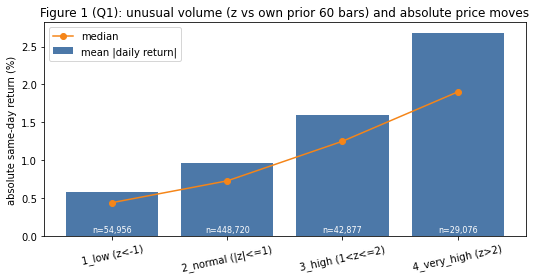

In [44]:
%%local
try:
    import matplotlib
    import matplotlib.pyplot as plt
    q1 = q1_sdf.sort_values("bucket")
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.bar(q1["bucket"], q1["mean_abs_ret"] * 100, color="#4C78A8", label="mean |daily return|")
    ax.plot(q1["bucket"], q1["median_abs_ret"] * 100, "o-", color="#F58518", label="median")
    for i, n in enumerate(q1["n"]):
        ax.annotate(f"n={int(n):,}", (i, 0.02), ha="center", va="bottom", fontsize=8, color="white")
    ax.set_ylabel("absolute same-day return (%)")
    ax.set_title("Figure 1 (Q1): unusual volume (z vs own prior 60 bars) and absolute price moves")
    ax.legend(); plt.xticks(rotation=12); plt.tight_layout(); plt.show()
except Exception as ex:
    print("Plot skipped (the table above is the evidence):", ex)

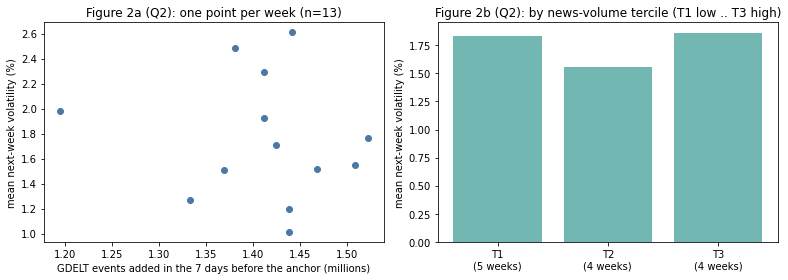

In [45]:
%%local
try:
    import matplotlib.pyplot as plt
    q2 = q2_week_sdf
    if len(q2) < 9:
        print(f"Figure 2 skipped: only {len(q2)} usable weeks (need >= 9 to interpret).")
    else:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].scatter(q2["news_events"] / 1e6, q2["mean_next_vol"] * 100, c="#4C78A8")
        axes[0].set_xlabel("GDELT events added in the 7 days before the anchor (millions)")
        axes[0].set_ylabel("mean next-week volatility (%)")
        axes[0].set_title(f"Figure 2a (Q2): one point per week (n={len(q2)})")
        g = q2.groupby("news_group").agg(weeks=("anchor_date", "count"), vol=("mean_next_vol", "mean"), ret=("mean_ret_next", "mean")).reset_index()
        axes[1].bar(g["news_group"] + "\n(" + g["weeks"].astype(str) + " weeks)", g["vol"] * 100, color="#72B7B2")
        axes[1].set_ylabel("mean next-week volatility (%)")
        axes[1].set_title("Figure 2b (Q2): by news-volume tercile (T1 low .. T3 high)")
        plt.tight_layout(); plt.show()
except Exception as ex:
    print("Plot skipped (the table above is the evidence):", ex)

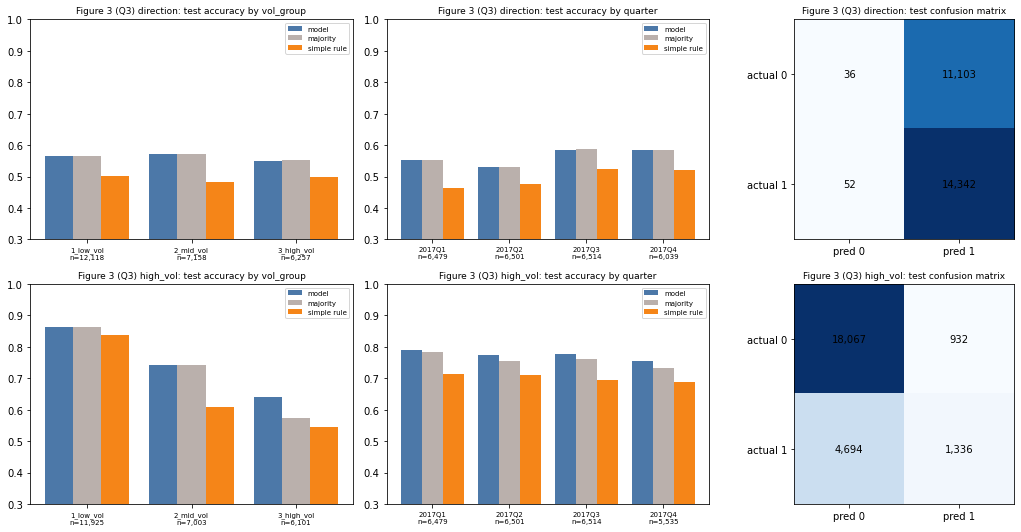

In [46]:
%%local
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    for r, task in enumerate(["direction", "high_vol"]):
        for c, dim in enumerate(["vol_group", "quarter"]):
            d = q3_sdf[(q3_sdf["task"] == task) & (q3_sdf["dim"] == dim)].sort_values("grp")
            ax, x = axes[r][c], range(len(d))
            ax.bar([i - 0.27 for i in x], d["model_acc"], 0.27, label="model", color="#4C78A8")
            ax.bar([i for i in x], d["majority_acc"], 0.27, label="majority", color="#BAB0AC")
            ax.bar([i + 0.27 for i in x], d["rule_acc"], 0.27, label="simple rule", color="#F58518")
            ax.set_xticks(list(x)); ax.set_xticklabels([f"{g}\nn={int(n):,}" for g, n in zip(d["grp"], d["n"])], fontsize=7)
            ax.set_ylim(0.3, 1.0); ax.set_title(f"Figure 3 (Q3) {task}: test accuracy by {dim}", fontsize=9); ax.legend(fontsize=7)
        m = cm_sdf[cm_sdf["task"] == task].pivot_table(index="label", columns="prediction", values="count", fill_value=0)
        axes[r][2].imshow(m.values, cmap="Blues")
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                axes[r][2].text(j, i, f"{int(m.values[i, j]):,}", ha="center", va="center")
        axes[r][2].set_xticks(range(m.shape[1])); axes[r][2].set_xticklabels([f"pred {int(v)}" for v in m.columns])
        axes[r][2].set_yticks(range(m.shape[0])); axes[r][2].set_yticklabels([f"actual {int(v)}" for v in m.index])
        axes[r][2].set_title(f"Figure 3 (Q3) {task}: test confusion matrix", fontsize=9)
    plt.tight_layout(); plt.show()
except Exception as ex:
    print("Plot skipped (the table above is the evidence):", ex)

### How to read the results (limitations, uncertainty, no causal claims)

* **Q1** shows that days with unusually high volume (relative to the same ticker's own recent history) coincide with larger absolute price moves. This is contemporaneous association; it is not evidence that volume *causes* moves.
* **Q2** is interpretable only if the acquired GDELT window gives enough weeks (guard above). The news signal is market-wide, so the effective sample is the number of weeks; alternative explanations (market-wide events, seasonality, the GDELT upward trend in volume) are not controlled.
* **Q3** shows where each model is reliable. A model that merely predicts the majority class matches the majority baseline everywhere — compare `model_acc`, `majority_acc`, `rule_acc` and `recall_positive`, not accuracy alone. Nothing is retuned on test results.
* Reported numbers are **source-price-ratio / model diagnostics**, not economic returns, and are not proof of historical investability.

## 5. Performance, memory and repetitions (report Section 6)

* **Stage timings** — every stage above was wall-clock timed with `stage(...)` (Spark actions run inside each stage, so lazy evaluation is included).
* **Repetitions** — the brief asks for the **median of three** repetitions. The benchmark below re-runs the *same* pipeline three times from the staged inputs: Task 2 (clean → features → splits → news) and the final fit + test scoring of both models with the frozen configuration. (The 14-experiment model-selection search is a one-off development activity and is timed separately above.)
* **Excluded** from timing, per the course Q&A: download, S3 → HDFS copy, cluster start-up. Hadoop Streaming and Hive times come from `run_log.csv` written by `scripts/stage2_streaming_and_hive.sh` and are added to give the end-to-end figure.
* **Reference vs alternative** — a *software-only* change (shuffle partitions + adaptive execution); hardware, release, replication and storage are identical. Change `ACTIVE_CONFIG` in Section 0.1, run again, and the comparison table at the end of this section lists both.

In [47]:
MAIN_LOG = list(CURRENT_LOG)            # the timings of the main run above
print(f"{'stage':62s} {'seconds':>9s}")
for r in MAIN_LOG:
    print(f"{r['stage']:62s} {r['seconds']:9.1f}")
print(f"{'TOTAL (main run, includes the 14-experiment search)':62s} {sum(r['seconds'] for r in MAIN_LOG if not r['stage'].startswith('2 PREPARE')):9.1f}")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

stage                                                            seconds
1a Spark quality audit of prices_typed                              10.0
2a clean+reject (PySpark)                                           13.0
2b features + weekly targets (PySpark)                              30.3
2 PREPARE (whole Task 2 in PySpark)                                 57.2
2d GDELT news features by anchor (PySpark)                           4.7
3 direction: 14 experiments (train->validation)                     98.9
3 direction: final fit (train) + test score + save model             8.8
3 high_vol: 14 experiments (train->validation)                      85.1
3 high_vol: final fit (train) + test score + save model              6.8
4 Q1 volume vs absolute return (PySpark)                             6.5
4 Q2 news volume vs subsequent behaviour (PySpark)                   2.6
4 Q3 model reliability by quarter / volatility group (PySpark)       5.0
TOTAL (main run, includes the 14-experiment search)

### 5.1 Three repetitions (median)

In [48]:
def run_benchmark_once(i):
    global CURRENT_LOG
    CURRENT_LOG = []
    root = f"{PREP}_bench{i}"
    t0 = time.time()
    prep = prepare(root, log_prefix=f"rep{i} ")
    for task in TASK_SPECS:
        with stage(f"rep{i} 3 {task}: final fit + test score") as st:
            fit_final(task, BEST[task], [], root=root)
    total = time.time() - t0
    return {"rep": i, "total_seconds": round(total, 2), "stages": {r["stage"].split(" ", 1)[1]: r["seconds"] for r in CURRENT_LOG}}

BENCH = []
for i in range(1, REPETITIONS + 1):
    print(f"\n----- repetition {i} of {REPETITIONS} -----")
    BENCH.append(run_benchmark_once(i))
CURRENT_LOG = MAIN_LOG

names = list(BENCH[0]["stages"])
med = {n: statistics.median(b["stages"][n] for b in BENCH) for n in names}
med_total = statistics.median(b["total_seconds"] for b in BENCH)
print(f"\n{'stage':58s} " + " ".join(f"{'rep'+str(b['rep']):>8s}" for b in BENCH) + f" {'median':>8s}")
for n in names:
    print(f"{n:58s} " + " ".join(f"{b['stages'][n]:8.1f}" for b in BENCH) + f" {med[n]:8.1f}")
print(f"{'END-TO-END (notebook stages)':58s} " + " ".join(f"{b['total_seconds']:8.1f}" for b in BENCH) + f" {med_total:8.1f}")
check("Benchmark: median notebook end-to-end under the 60-minute marking timeout", "< 3600 s", f"{med_total:.0f} s", ok=med_total < 3600,
      evidence="perf json")

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…


----- repetition 1 of 3 -----
[stage] rep1 2a clean+reject (PySpark): 8.12 s
[stage] rep1 2b features + weekly targets (PySpark): 20.6 s
[stage] rep1 3 direction: final fit + test score: 3.84 s
[stage] rep1 3 high_vol: final fit + test score: 3.78 s

----- repetition 2 of 3 -----
[stage] rep2 2a clean+reject (PySpark): 7.66 s
[stage] rep2 2b features + weekly targets (PySpark): 22.95 s
[stage] rep2 3 direction: final fit + test score: 3.79 s
[stage] rep2 3 high_vol: final fit + test score: 3.72 s

----- repetition 3 of 3 -----
[stage] rep3 2a clean+reject (PySpark): 7.95 s
[stage] rep3 2b features + weekly targets (PySpark): 19.55 s
[stage] rep3 3 direction: final fit + test score: 3.78 s
[stage] rep3 3 high_vol: final fit + test score: 3.8 s

stage                                                          rep1     rep2     rep3   median
2a clean+reject (PySpark)                                       8.1      7.7      8.0      8.0
2b features + weekly targets (PySpark)                 

### 5.2 Data sizes, shell-stage timings and measured memory

In [49]:
def dir_bytes(path):
    try:
        p = spark._jvm.org.apache.hadoop.fs.Path(path)
        return p.getFileSystem(spark._jsc.hadoopConfiguration()).getContentSummary(p).getLength()
    except Exception:
        return None

sizes = {"raw_prices_bytes": dir_bytes(f"hdfs:///raw/prices/{VERSION}") if IS_EMR else None,
         "raw_gdelt_bytes":  dir_bytes(f"hdfs:///raw/gdelt/{VERSION}") if IS_EMR else None,
         "prepared_bytes":   dir_bytes(PREP), "price_rows": REC["raw_rows"], "gdelt_days": gd_summary["days"],
         "gdelt_events": gd_summary["events"]}
print("data sizes:", sizes)

shell_total, shell_rows = None, []
try:    # run_log.csv from stage2_streaming_and_hive.sh (copied to HDFS by scripts/emr_run_all.sh)
    rl = spark.read.option("header", True).csv(f"hdfs:///evidence/{VERSION}/run_log.csv")
    shell_rows = [r.asDict() for r in rl.select("stage", "engine", "seconds", "application_ids").collect()]
    shell_total = sum(float(r["seconds"]) for r in shell_rows)
    for r in shell_rows:
        print(f"  shell stage {r['stage']:28s} {r['engine']:18s} {float(r['seconds']):7.0f} s  {r['application_ids']}")
except Exception as ex:
    print("run_log.csv not found in HDFS (run scripts/emr_run_all.sh first). Shell-stage seconds not included:", str(ex)[:100])

def executor_memory():
    """Measured per-executor memory from the Spark UI REST API (peak JVM heap, storage memory used / max)."""
    out = {}
    try:
        import urllib.request
        url = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/executors"
        for e in json.load(urllib.request.urlopen(url, timeout=10)):
            pm = e.get("peakMemoryMetrics", {}) or {}
            out[e["id"]] = {"max_storage_MiB": round(e["maxMemory"] / 2**20), "storage_used_MiB": round(e["memoryUsed"] / 2**20),
                            "peak_jvm_heap_MiB": round(pm.get("JVMHeapMemory", 0) / 2**20),
                            "peak_offheap_MiB": round(pm.get("JVMOffHeapMemory", 0) / 2**20),
                            "gc_time_s": round(e.get("totalGCTime", 0) / 1000, 1), "task_time_s": round(e.get("totalDuration", 0) / 1000, 1)}
    except Exception as ex:
        out["unavailable"] = str(ex)[:150]
    return out

MEMORY = executor_memory()
print("measured executor memory (MiB):", json.dumps(MEMORY, indent=2))
print("YARN view (cross-check): on the primary node run  yarn application -list  and open the Spark UI > Executors tab.")

end_to_end = None if shell_total is None else shell_total + med_total
PERF = {"version": VERSION, "config": ACTIVE_CONFIG, "config_note": CONFIGS[ACTIVE_CONFIG], "recorded_utc": utc_now(),
        "application_id": sc.applicationId, "spark_version": spark.version, "is_emr": IS_EMR, "sizes": sizes,
        "median_notebook_seconds": med_total, "repetition_seconds": [b["total_seconds"] for b in BENCH],
        "median_stage_seconds": med, "shell_stage_seconds": shell_total, "end_to_end_median_seconds": end_to_end,
        "executor_memory": MEMORY, "spark_conf": ENVIRONMENT["spark_conf"]}
write_text(f"{OUT}/evidence/perf/{VERSION}_{ACTIVE_CONFIG}.json", json.dumps(PERF, indent=2, default=str))
print(f"\nmedian notebook time {med_total:.0f} s" + ("" if end_to_end is None else f";  shell stages {shell_total:.0f} s;  END-TO-END {end_to_end:.0f} s ({end_to_end/60:.1f} min)"))

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

data sizes: {'raw_prices_bytes': 29580549, 'raw_gdelt_bytes': 6944840235, 'prepared_bytes': 52071634, 'price_rows': 619040, 'gdelt_days': 91, 'gdelt_events': 18369793}
  shell stage stage2a_streaming_audit      hadoop_streaming       212 s  application_1793775642011_0002
  shell stage stage2b_hive_register        hive_tez                15 s  None
  shell stage stage2c_hive_transform       hive_tez                33 s  application_1793775642011_0004
  shell stage stage2d_hive_results         hive_tez                25 s  application_1793775642011_0005
measured executor memory (MiB): {
  "driver": {
    "max_storage_MiB": 1049,
    "storage_used_MiB": 268,
    "peak_jvm_heap_MiB": 1355,
    "peak_offheap_MiB": 370,
    "gc_time_s": 6.1,
    "task_time_s": 687.3
  },
  "2": {
    "max_storage_MiB": 3097,
    "storage_used_MiB": 267,
    "peak_jvm_heap_MiB": 2442,
    "peak_offheap_MiB": 265,
    "gc_time_s": 8.1,
    "task_time_s": 518.6
  },
  "1": {
    "max_storage_MiB": 3097,
    "st

### 5.3 Comparison table: development vs full profile, reference vs alternative configuration

This reads every `perf/*.json` saved so far (one per `VERSION` × `ACTIVE_CONFIG` run). To fill the table: run the notebook for the development profile and the full profile, each with `ACTIVE_CONFIG = "reference"` and then `"alternative"`. Compare only runs with identical inputs and identical output checks.

In [50]:
try:
    pf = spark.read.option("multiLine", True).json(f"{OUT}/evidence/perf/*.json")
    show(pf.select("version", "config", F.col("sizes.price_rows").alias("price_rows"), F.col("sizes.gdelt_days").alias("gdelt_days"),
                   F.col("sizes.raw_gdelt_bytes").alias("raw_gdelt_bytes"), F.round("median_notebook_seconds", 1).alias("median_notebook_s"),
                   F.round("shell_stage_seconds", 1).alias("shell_s"), F.round("end_to_end_median_seconds", 1).alias("end_to_end_s"),
                   "repetition_seconds", "recorded_utc"), 20)
except Exception as ex:
    print("No comparison yet:", str(ex)[:120])

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

+-------------------+---------+----------+----------+---------------+-----------------+-------+------------+---------------------+-------------------------+
|version            |config   |price_rows|gdelt_days|raw_gdelt_bytes|median_notebook_s|shell_s|end_to_end_s|repetition_seconds   |recorded_utc             |
+-------------------+---------+----------+----------+---------------+-----------------+-------+------------+---------------------+-------------------------+
|v2026-10-29-q1-2016|reference|619040    |91        |6944840235     |46.9             |285.0  |331.9       |[46.91, 47.87, 44.91]|2026-11-04T08:33:43+00:00|
+-------------------+---------+----------+----------+---------------+-----------------+-------+------------+---------------------+-------------------------+

## 6. Saved-model reload in a fresh session (Task 3.3)

The complete `PipelineModel` (median `Imputer` → `VectorAssembler` → `StandardScaler` → classifier) was saved above to HDFS **and** S3. This section loads it **without retraining** and re-scores the test set.

**To make it a true fresh-session test:** `Kernel → Restart`, run only the **Section 0.1 parameters cell and its two following cells (0.2 helpers, 0.3 environment)** — or simply run this cell alone, it is self-contained — and then this section. A new Spark `application_id` proves the session is fresh. Expected: identical class predictions and probabilities within `TOL = 1e-9`.

In [51]:
# ---- self-contained: works right after a kernel restart (does not need any earlier cell)
import json, datetime
from pyspark.ml import PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

_VERSION, _BUCKET, _CONFIG = globals().get("VERSION", "v2026-10-27"), globals().get("BUCKET", "inf2006-team07-bigdata"), globals().get("ACTIVE_CONFIG", "reference")
_TOL = globals().get("TOL", 1e-9)
_EMR = "amzn" in spark.version
if _EMR:
    _PREP, _MODEL_PATHS = f"hdfs:///prepared/{_VERSION}/{_CONFIG}", [f"hdfs:///models/{_VERSION}", f"s3://{_BUCKET}/notebook_outputs/{_VERSION}/models"]
    _EVD = f"s3://{_BUCKET}/notebook_outputs/{_VERSION}/evidence/{_CONFIG}"
else:
    import os
    _R = os.path.abspath("work/nb")
    _PREP, _MODEL_PATHS = f"file://{_R}/prepared/{_VERSION}/{_CONFIG}", [f"file://{_R}/models/{_VERSION}", f"file://{_R}/out/{_VERSION}/models"]
    _EVD = f"file://{_R}/out/{_VERSION}/evidence/{_CONFIG}"

def _exists(p):
    jp = spark._jvm.org.apache.hadoop.fs.Path(p)
    return jp.getFileSystem(spark._jsc.hadoopConfiguration()).exists(jp)

def _wt(path, text):
    jp = spark._jvm.org.apache.hadoop.fs.Path(path)
    o = jp.getFileSystem(spark._jsc.hadoopConfiguration()).create(jp, True); o.write(bytearray(text.encode("utf-8"))); o.close()

RELOAD = {"application_id_reload_session": spark.sparkContext.applicationId, "checked_utc": datetime.datetime.utcnow().isoformat(timespec="seconds"),
          "tolerance": _TOL, "results": []}
try:
    env = json.loads("\n".join(r[0] for r in spark.read.text(f"{_EVD}/environment.json").collect()))
    RELOAD["application_id_training_session"] = env["application_id"]
    print("training session :", env["application_id"], "\nreload session   :", RELOAD["application_id_reload_session"],
          "\nfresh session    :", env["application_id"] != RELOAD["application_id_reload_session"])
except Exception as ex:
    print("environment.json not found (training evidence missing?):", str(ex)[:100])

all_ok = True
for task in ("direction", "high_vol"):
    for base in _MODEL_PATHS:
        path = f"{base}/{task}"
        rec = {"task": task, "model_path": path, "checks": []}
        def chk(name, ok, detail=""):
            global all_ok
            rec["checks"].append({"check": name, "passed": bool(ok), "detail": str(detail)}); all_ok &= bool(ok)
            print(("PASS " if ok else "FAIL ") + f"[{task}] {name} {detail}   <- {path}")
        has_meta, has_stages = _exists(f"{path}/metadata"), _exists(f"{path}/stages")
        chk("model folder has metadata/", has_meta); chk("model folder has stages/", has_stages)
        if not (has_meta and has_stages):
            rec["error"] = "MISSING or INCOMPATIBLE model files"; RELOAD["results"].append(rec); continue
        try:
            model = PipelineModel.load(path)
        except Exception as ex:
            chk("PipelineModel.load (no retraining)", False, str(ex)[:150]); RELOAD["results"].append(rec); continue
        chk("PipelineModel.load (no retraining)", True, " -> ".join(type(s).__name__ for s in model.stages))
        test = spark.read.parquet(f"{_PREP}/{task}/test")
        saved = spark.read.parquet(f"{_PREP}/pred_{task}").select("ticker", "anchor_date", F.col("prediction").alias("pred_saved"), F.col("prob").alias("prob_saved"))
        new = model.transform(test).withColumn("prob_new", vector_to_array("probability")[1])
        j = new.join(saved, ["ticker", "anchor_date"])
        n_new, n_saved, n_join = new.count(), saved.count(), j.count()
        chk("row counts match (re-scored / saved / joined)", n_new == n_saved == n_join, f"{n_new}/{n_saved}/{n_join}")
        mx = j.agg(F.max(F.abs(F.col("prob_new") - F.col("prob_saved")))).first()[0]
        chk(f"max |probability difference| <= {_TOL}", mx is not None and mx <= _TOL, f"max_abs_diff={mx}")
        flips = j.where(F.col("prediction") != F.col("pred_saved")).count()
        chk("class predictions identical", flips == 0, f"differing={flips}")
        rec["max_abs_prob_diff"] = mx
        RELOAD["results"].append(rec)
RELOAD["all_checks_passed"] = all_ok
print("\nRELOAD VERDICT:", "ALL PASSED" if all_ok else "SOME CHECKS FAILED - see FAIL lines above")
_wt(f"{_EVD}/t3_reload.json", json.dumps(RELOAD, indent=2, default=str))

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

training session : application_1793775642011_0010 
reload session   : application_1793775642011_0010 
fresh session    : False
PASS [direction] model folder has metadata/    <- hdfs:///models/v2026-10-29-q1-2016/direction
PASS [direction] model folder has stages/    <- hdfs:///models/v2026-10-29-q1-2016/direction
PASS [direction] PipelineModel.load (no retraining) ImputerModel -> VectorAssembler -> StandardScalerModel -> LogisticRegressionModel   <- hdfs:///models/v2026-10-29-q1-2016/direction
PASS [direction] row counts match (re-scored / saved / joined) 25533/25533/25533   <- hdfs:///models/v2026-10-29-q1-2016/direction
PASS [direction] max |probability difference| <= 1e-09 max_abs_diff=0.0   <- hdfs:///models/v2026-10-29-q1-2016/direction
PASS [direction] class predictions identical differing=0   <- hdfs:///models/v2026-10-29-q1-2016/direction
PASS [direction] model folder has metadata/    <- s3://inf2006-team07-bigdata-1-310947418945-us-east-1-an/notebook_outputs/v2026-10-29-q1-201

## 7. Verification record and run summary

Every check printed in this notebook, in the format the brief asks for (check · expected · actual · pass/fail · evidence location). **Failed checks are reported, not hidden.** If you restarted the kernel for Section 6, this table lists only checks run since then — for the full record use the saved `verification_record.json` from the main run.

In [52]:
try:
    n_pass = sum(c["passed"] for c in CHECKS)
    print(f"{n_pass} of {len(CHECKS)} checks passed\n")
    for c in CHECKS:
        print(("PASS" if c["passed"] else "FAIL"), "|", c["check"], "| expected:", c["expected"], "| actual:", c["actual"], "|", c["evidence"])
    summary = {"environment": ENVIRONMENT, "stage_timings_main_run": MAIN_LOG, "checks": CHECKS,
               "prepared": PREPARED, "model_results": {t: {k: v for k, v in r.items() if k != "experiments"} for t, r in MODEL_RESULTS.items()},
               "performance": PERF, "reload": RELOAD, "outputs": {"evidence": EV, "models_s3_or_primary": MODELS_OUT, "models_hdfs": MODELS_HDFS,
                                                                   "prepared": PREP}}
    save_json("verification_record.json", summary)
    print("\nsaved:", f"{EV}/verification_record.json")
except NameError as ex:
    print("Main-run variables are not in this session (kernel was restarted). Open the saved record instead:", ex)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

34 of 34 checks passed

PASS | Task1 prices rows_total (Spark vs local Python profile) | expected: 619040 | actual: 619040 | evidence/local/quality_summary.json
PASS | Task1 prices tickers (Spark vs local Python profile) | expected: 505 | actual: 505 | evidence/local/quality_summary.json
PASS | Task1 prices date_min (Spark vs local Python profile) | expected: 2013-02-08 | actual: 2013-02-08 | evidence/local/quality_summary.json
PASS | Task1 prices date_max (Spark vs local Python profile) | expected: 2018-02-07 | actual: 2018-02-07 | evidence/local/quality_summary.json
PASS | Task1 prices rows_up_to_2017_12_29 (Spark vs local Python profile) | expected: 605910 | actual: 605910 | evidence/local/quality_summary.json
PASS | Task1 prices empty_open (Spark vs local Python profile) | expected: 11 | actual: 11 | evidence/local/quality_summary.json
PASS | Task1 prices empty_high (Spark vs local Python profile) | expected: 8 | actual: 8 | evidence/local/quality_summary.json
PASS | Task1 prices e

### Where everything is saved (copy into the submission ZIP, see `docs/RUN_ON_EMR.md` step 10)

| Artefact | Location |
|---|---|
| Notebook with outputs | JupyterHub → File → Download as `.ipynb` (also auto-saved to `s3://<bucket>/jupyter/`) |
| Evidence JSON (reconciliation, splits, model results, reload, verification, performance) | `s3://<bucket>/notebook_outputs/<VERSION>/evidence/` |
| Saved `PipelineModel`s (direction, high_vol) | `s3://<bucket>/notebook_outputs/<VERSION>/models/` and `hdfs:///models/<VERSION>/` |
| Prepared datasets, predictions | `hdfs:///prepared/<VERSION>/<config>/` |
| Shell-stage evidence (Stage 1–2) | `evidence/<cluster-folder>/` in the repo clone on the primary node |